## Analyze the impact of different regularization techniques on model performance.

We will:

Use the MNIST dataset

Train 5 models:

1. Baseline (no regularization)

2. L1 Regularization

3. L2 Regularization

4. Dropout

5. Batch Normalization

Compare:

1. Training accuracy

2. Validation accuracy

3. Loss curves

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten
from tensorflow.keras.regularizers import l1, l2
import matplotlib.pyplot as plt

In [2]:
# Load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize
x_train = x_train / 255.0
x_test = x_test / 255.0

# Flatten
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Function to build model
def build_model(reg_type=None):
    model = Sequential()
    
    if reg_type == "l1":
        model.add(Dense(256, activation="relu", input_shape=(784,), kernel_regularizer=l1(0.001)))
    elif reg_type == "l2":
        model.add(Dense(256, activation="relu", input_shape=(784,), kernel_regularizer=l2(0.001)))
    else:
        model.add(Dense(256, activation="relu", input_shape=(784,)))
        
    if reg_type == "dropout":
        model.add(Dropout(0.4))
        
    if reg_type == "batchnorm":
        model.add(BatchNormalization())
    
    model.add(Dense(128, activation="relu"))
    
    model.add(Dense(10, activation="softmax"))
    
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In [3]:
# Build models
models = {
    "Baseline": build_model(),
    "L1 Regularization": build_model("l1"),
    "L2 Regularization": build_model("l2"),
    "Dropout": build_model("dropout"),
    "BatchNorm": build_model("batchnorm"),
}

In [4]:
# Train models
histories = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    history = model.fit(
        x_train, y_train, 
        epochs=10, batch_size=128, 
        validation_split=0.2,
        verbose=0
    )
    histories[name] = history


Training Baseline...

Training L1 Regularization...

Training L2 Regularization...

Training Dropout...

Training BatchNorm...


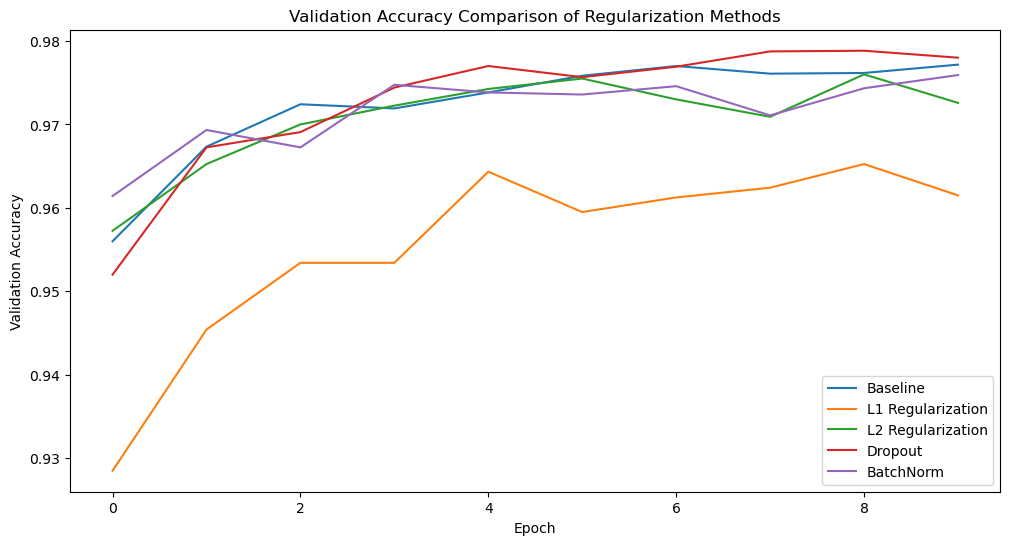

In [5]:
# Plot accuracy comparison
plt.figure(figsize=(12, 6))
for name, history in histories.items():
    plt.plot(history.history["val_accuracy"], label=name)

plt.title("Validation Accuracy Comparison of Regularization Methods")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

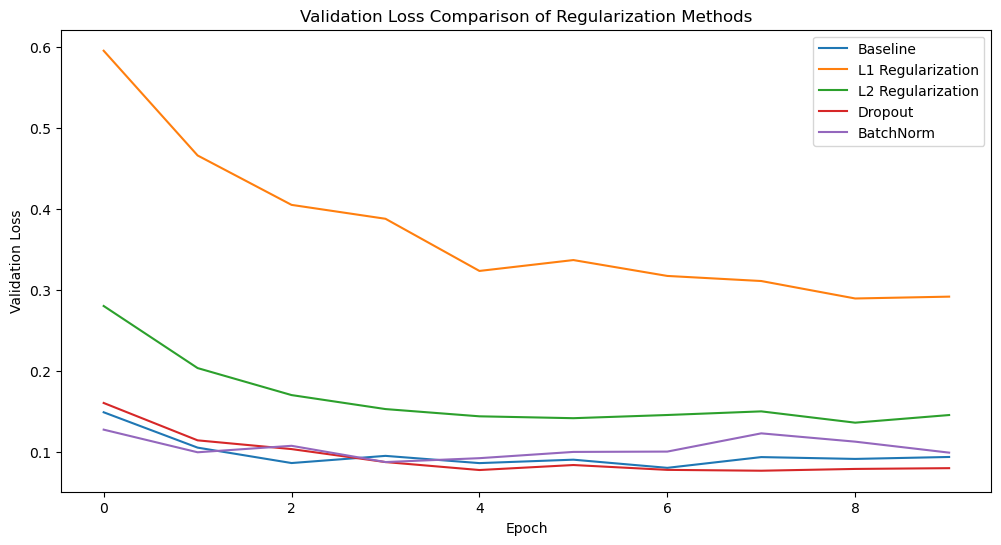

In [6]:
# Plot loss comparison
plt.figure(figsize=(12, 6))
for name, history in histories.items():
    plt.plot(history.history["val_loss"], label=name)

plt.title("Validation Loss Comparison of Regularization Methods")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.show()